# Studi Kasus 2 — *Bridging Global Infrastructure to Address Local Challenge with HPC*

**Pemateri:** Asst. Prof. Dr. Worawan Diaz Carballo (Thammasat University, Thailand)
**Video:** https://www.youtube.com/live/qeWpf9uXBqE
**Seri:** Informatics Practitioner Lecture Series 2026 — Prodi Informatika Universitas Bengkulu

---

## Ringkasan materi pemateri

1. **Kecepatan komputer diukur dalam FLOPS** (*floating point operations per second*) karena sebagian besar data dunia
   adalah bilangan real yang direpresentasikan sebagai *floating point* (32/64/128 bit). Superkomputer tercepat kini
   berada di level **exaFLOPS** (10¹⁸). Peringkat diukur dengan *benchmark* **LINPACK** (aljabar linear, 64-bit) di
   situs top500.org, dibuat oleh Jack Dongarra.
2. Program yang paling banyak berjalan di superkomputer adalah **simulasi** fenomena nyata (molekul virus, iklim bumi /
   *Destination Earth*, evakuasi bencana, prakiraan cuaca 45 menit di Thailand).
3. Evolusi pusat superkomputer: laboratorium → pusat nasional → fasilitas lintas negara & kapabilitas AI nasional
   (CPU + GPU + QPU). Tantangannya kini adalah **menjembatani infrastruktur global dengan masalah lokal** (SDG):
   banjir, pertanian, wabah, PM2.5, tagihan listrik.
4. Contoh proyek *HPC Ignite*: **ko-simulasi energi gedung** (EnergyPlus + *agent-based simulation* untuk manusia dan
   kebijakan pemakaian gedung), rute EV, *molecular docking* tanaman lokal untuk obat asma, penerjemah bahasa minoritas.
5. Cara memakai HPC: akun & portal → **SSH dengan kunci publik/privat** → terminal Linux → tulis **batch script**
   (minta *node*/prosesor) → *submit job* → unduh hasil → visualisasi.
6. Mahasiswa informatika didorong menjadi **integrator**: orang yang merancang *workflow* dari masalah lokal → data →
   model → komputasi HPC → aplikasi bagi pengguna, bekerja bersama pakar domain. Jalurnya: *learner → practitioner*
   (mis. ikut kompetisi APAC HPC-AI).

## Latar belakang studi kasus

Mengikuti contoh pemateri, kita angkat **masalah lokal: tagihan listrik gedung kampus**. Tagihan listrik berasal dari
**perilaku manusia** di dalam gedung (menyalakan AC, lupa mematikan, memilih suhu terlalu dingin), bukan dari gedungnya
saja. Pengelola kampus ingin menguji beberapa **kebijakan hemat energi** sebelum diterapkan, dengan **kendala**:
laboratorium biologi (inkubator/freezer) tidak boleh dimatikan.

Karena perilaku manusia acak, setiap kebijakan harus disimulasikan **ratusan kali (Monte Carlo)** — beban komputasi
yang cocok dikerjakan **paralel**, dari laptop/Colab hingga klaster HPC.

## Tujuan
1. Memahami FLOPS, presisi *floating point*, dan *benchmark* ala LINPACK.
2. Membangun simulasi berbasis agen (disederhanakan) konsumsi listrik gedung kampus di Bengkulu.
3. Menjalankan simulasi secara serial vs paralel, mengukur *speedup*, efisiensi, dan Hukum Amdahl.
4. Menyiapkan *batch script* SLURM agar simulasi dapat dijalankan di klaster HPC (mis. HPC BRIN / Mahameru).

## 0. Persiapan & informasi mesin

In [1]:
import os, time, platform, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from concurrent.futures import ProcessPoolExecutor

sns.set_theme(style="whitegrid")
N_CPU = os.cpu_count()
print("Sistem  :", platform.platform())
print("Prosesor:", platform.processor() or "(tidak terbaca)")
print("Jumlah CPU logis:", N_CPU)

Sistem  : Windows-11-10.0.26200-SP0
Prosesor: Intel64 Family 6 Model 158 Stepping 12, GenuineIntel
Jumlah CPU logis: 6


## 1. FLOPS — seberapa cepat mesin kita?

Perkalian matriks $n \times n$ membutuhkan $\approx 2n^3$ operasi *floating point*. Dengan mengukur waktunya,
kita bisa menghitung GFLOPS (10⁹ FLOPS).

In [2]:
def gflops_python_murni(n=120):
    A = [[float(i * j % 7) for j in range(n)] for i in range(n)]
    B = [[float((i + j) % 5) for j in range(n)] for i in range(n)]
    t0 = time.perf_counter()
    C = [[sum(A[i][k] * B[k][j] for k in range(n)) for j in range(n)] for i in range(n)]
    dt = time.perf_counter() - t0
    return 2 * n**3 / dt / 1e9, dt

def gflops_numpy(n, dtype, ulang=3):
    rng = np.random.default_rng(0)
    A = rng.random((n, n)).astype(dtype); B = rng.random((n, n)).astype(dtype)
    A @ B                                       # pemanasan
    t0 = time.perf_counter()
    for _ in range(ulang):
        A @ B
    dt = (time.perf_counter() - t0) / ulang
    return 2 * n**3 / dt / 1e9, dt

hasil = []
g, dt = gflops_python_murni(); hasil.append(("Python murni (loop)", 120, "float64", g, dt))
for n in [500, 1000, 2000]:
    for dtype in [np.float64, np.float32]:
        g, dt = gflops_numpy(n, dtype); hasil.append(("NumPy / BLAS", n, np.dtype(dtype).name, g, dt))
flops = pd.DataFrame(hasil, columns=["implementasi", "n", "presisi", "GFLOPS", "detik"])
flops

,implementasi,n,presisi,GFLOPS,detik
0,Python murni (loop),120,float64,0.019851,0.174096
1,NumPy / BLAS,500,float64,78.002309,0.003205
2,NumPy / BLAS,500,float32,267.895414,0.000933
3,NumPy / BLAS,1000,float64,132.048937,0.015146
4,NumPy / BLAS,1000,float32,262.299669,0.007625
5,NumPy / BLAS,2000,float64,134.021871,0.119383
6,NumPy / BLAS,2000,float32,305.101100,0.052442


Pelajaran pertama HPC: **algoritma & pustaka yang tepat** (BLAS yang memakai instruksi vektor + banyak *core*)
bisa ribuan kali lebih cepat daripada *loop* Python biasa. Presisi 32-bit lebih cepat daripada 64-bit, tetapi kurang teliti.

### 1.1 Mini-LINPACK
LINPACK menyelesaikan sistem persamaan linear $Ax=b$ (64-bit). Jumlah operasinya $\tfrac{2}{3}n^3 + 2n^2$.
Hasil dianggap sah bila **residu** kecil.

In [3]:
def mini_linpack(n):
    rng = np.random.default_rng(1)
    A = rng.random((n, n)); b = rng.random(n)
    t0 = time.perf_counter(); x = np.linalg.solve(A, b); dt = time.perf_counter() - t0
    ops = 2 / 3 * n**3 + 2 * n**2
    residu = np.linalg.norm(A @ x - b) / (np.linalg.norm(A) * np.linalg.norm(x) * n * np.finfo(float).eps)
    return {"n": n, "detik": dt, "GFLOPS": ops / dt / 1e9, "residu_ternormalisasi": residu}

linpack = pd.DataFrame([mini_linpack(n) for n in [1000, 2000, 4000]])
display(linpack)

gf_kita = linpack.GFLOPS.max()
EL_CAPITAN = 1.742e18     # Rmax El Capitan (TOP500 Nov 2024) — cek daftar terbaru di top500.org
print(f"Mesin ini ≈ {gf_kita:,.1f} GFLOPS")
print(f"El Capitan ≈ {EL_CAPITAN / 1e9:,.0f} GFLOPS → ±{EL_CAPITAN / (gf_kita * 1e9):,.0f} kali lebih cepat")
print("Satu detik kerja El Capitan setara ±"
      f"{EL_CAPITAN / (gf_kita * 1e9) / 86400 / 365:,.0f} tahun kerja mesin ini.")

,n,detik,GFLOPS,residu_ternormalisasi
0,1000,0.022736,29.410169,0.000819
1,2000,0.094925,56.269162,0.000675
2,4000,0.555174,76.910381,0.000543


Mesin ini ≈ 76.9 GFLOPS
El Capitan ≈ 1,742,000,000 GFLOPS → ±22,649,738 kali lebih cepat
Satu detik kerja El Capitan setara ±1 tahun kerja mesin ini.


> Catatan: pemateri menyebut daftar TOP500 Juni 2026 sudah dipuncaki mesin baru; angka di atas memakai El Capitan
> sebagai pembanding yang terdokumentasi. Periksa top500.org untuk daftar terbaru.

### 1.2 Kenapa harus *floating point* 64-bit?
Bilangan real tidak dapat direpresentasikan persis dalam biner. Kesalahan kecil menumpuk pada simulasi panjang.

In [4]:
print("0.1 + 0.2 == 0.3 ?", 0.1 + 0.2 == 0.3, "→ nilai sebenarnya:", repr(0.1 + 0.2))
langkah = 1_000_000
for dtype in [np.float16, np.float32, np.float64]:
    total = np.cumsum(np.full(langkah, 0.1, dtype=dtype), dtype=dtype)[-1]
    print(f"{np.dtype(dtype).name:8s}: 0.1 dijumlah {langkah:,}x = {float(total):,.6f} (seharusnya 100,000)")

0.1 + 0.2 == 0.3 ? False → nilai sebenarnya: 0.30000000000000004
float16 : 0.1 dijumlah 1,000,000x = 256.000000 (seharusnya 100,000)
float32 : 0.1 dijumlah 1,000,000x = 100,958.343750 (seharusnya 100,000)
float64 : 0.1 dijumlah 1,000,000x = 100,000.000001 (seharusnya 100,000)


## 2. Simulasi berbasis agen: konsumsi listrik gedung kampus

### 2.1 Model (disederhanakan)
* **Gedung**: ruang kelas, lab komputer, perpustakaan, ruang dosen, dan **lab biologi** (inkubator/freezer selalu
  menyala — *kendala*).
* **Agen**: mahasiswa & dosen yang hadir per jam mengikuti pola hari kerja/akhir pekan. Saat ruangan terisi, agen
  menyalakan AC dengan suhu kesukaannya; saat ruangan kosong, ada peluang agen **lupa mematikan AC**.
* **Cuaca Bengkulu**: suhu luar mengikuti siklus harian ±25–32 °C.
* **Daya AC** naik bila selisih suhu luar–setelan besar (±7% per °C, aturan praktis).
* **Tarif** listrik diasumsikan Rp1.444,70/kWh.

### 2.2 Kebijakan yang diuji (mirip contoh pemateri)
| Kode | Kebijakan |
|---|---|
| P0 | *Baseline* — tanpa aturan |
| P1 | AC hanya boleh menyala 08.00–17.00 (*auto-off* di luar jam itu) |
| P2 | Setelan AC minimal 25 °C |
| P3 | Perpustakaan tutup Sabtu–Minggu |
| P4 | Lab komputer tutup 20.00–08.00 |
| P5 | Kombinasi P1–P4 |

Model ditulis ke file `sim_gedung.py` — persis seperti di HPC, kode simulasi biasanya berupa *script* yang dipanggil
oleh *job scheduler*. File modul juga dibutuhkan agar `multiprocessing` dapat memanggil fungsi di proses lain.

In [5]:
KODE_SIMULASI = r'''
import numpy as np

TARIF = 1444.70  # Rp/kWh (asumsi)
# nama, tipe, jumlah ruang, kapasitas, kW AC, kW beban lain saat dipakai, kW selalu menyala
RUANG = [
    ("Kelas",        "kelas",  12, 40, 3.0, 0.6, 0.0),
    ("Lab Komputer", "lab",     4, 40, 5.0, 6.0, 0.2),
    ("Perpustakaan", "perpus",  1, 120, 15.0, 2.0, 0.3),
    ("Ruang Dosen",  "dosen",   8,  4, 2.0, 0.4, 0.0),
    ("Lab Biologi",  "bio",     1, 20, 4.0, 1.0, 3.0),
]
KEBIJAKAN = {
    "P0 Baseline": dict(),
    "P1 AC 08-17": dict(jam_ac=(8, 17)),
    "P2 Setelan >= 25C": dict(setelan_min=25.0),
    "P3 Perpus tutup akhir pekan": dict(perpus_tutup_weekend=True),
    "P4 Lab tutup 20-08": dict(lab_tutup_malam=True),
    "P5 Kombinasi": dict(jam_ac=(8, 17), setelan_min=25.0, perpus_tutup_weekend=True, lab_tutup_malam=True),
}

def peluang_hadir(tipe, jam, akhir_pekan):
    """Profil kehadiran agen per jam (0..1)."""
    if tipe == "bio":
        base = 0.6 if 8 <= jam < 17 else 0.05            # peneliti kadang lembur
        return base * (0.4 if akhir_pekan else 1.0)
    if akhir_pekan:
        return {"perpus": 0.25, "lab": 0.08}.get(tipe, 0.02) if 8 <= jam < 18 else 0.0
    if tipe == "kelas":  return 0.75 if 7 <= jam < 17 else (0.15 if 17 <= jam < 21 else 0.0)
    if tipe == "lab":    return 0.65 if 8 <= jam < 17 else (0.35 if 17 <= jam < 23 else 0.05)
    if tipe == "perpus": return 0.6 if 8 <= jam < 20 else 0.0
    if tipe == "dosen":  return 0.7 if 8 <= jam < 16 else (0.1 if 16 <= jam < 19 else 0.0)
    return 0.0

def jalankan(kebijakan, seed, hari=30, p_lupa=0.35):
    """Satu replikasi Monte Carlo. Mengembalikan energi (kWh), biaya, dan indikator kenyamanan."""
    aturan = KEBIJAKAN[kebijakan]
    rng = np.random.default_rng(seed)
    unit = [(nama, tipe, kap, kw_ac, kw_lain, kw_tetap) for nama, tipe, n, kap, kw_ac, kw_lain, kw_tetap in RUANG
            for _ in range(n)]
    ac_on = np.array([tipe == "bio" for _, tipe, *_ in unit])   # AC lab biologi wajib menyala 24 jam
    setelan = np.full(len(unit), 24.0)
    kwh = 0.0; jam_tidak_nyaman = 0; pelanggaran_bio = 0
    for d in range(hari):
        akhir_pekan = d % 7 in (5, 6)
        for jam in range(24):
            t_luar = 28.5 + 3.5 * np.sin(2 * np.pi * (jam - 9) / 24) + rng.normal(0, 0.8)
            for i, (nama, tipe, kap, kw_ac, kw_lain, kw_tetap) in enumerate(unit):
                tutup = (aturan.get("perpus_tutup_weekend") and tipe == "perpus" and akhir_pekan) or \
                        (aturan.get("lab_tutup_malam") and tipe == "lab" and (jam >= 20 or jam < 8))
                hadir = 0 if tutup else rng.binomial(kap, peluang_hadir(tipe, jam, akhir_pekan))
                if hadir > 0:
                    if not ac_on[i]:
                        pref = rng.normal(22.5, 1.5, size=min(hadir, 5)).min()   # agen paling "kedinginan" menang
                        setelan[i] = max(pref, aturan.get("setelan_min", 16.0))
                    ac_on[i] = True
                elif ac_on[i] and tipe != "bio":
                    ac_on[i] = rng.random() < p_lupa                           # agen lupa mematikan AC
                jam_ac = aturan.get("jam_ac")
                if jam_ac and tipe != "bio" and not (jam_ac[0] <= jam < jam_ac[1]):
                    if hadir > 0: jam_tidak_nyaman += 1
                    ac_on[i] = False
                if tipe == "bio" and not ac_on[i]:
                    pelanggaran_bio += 1                                       # kendala dilanggar
                if ac_on[i]:
                    faktor = min(max(1 + 0.07 * (t_luar - setelan[i] - 4), 0.3), 1.6)
                    kwh += kw_ac * faktor
                if hadir > 0:
                    kwh += kw_lain * min(1.0, 0.3 + hadir / kap)
                kwh += kw_tetap
    return {"kebijakan": kebijakan, "seed": seed, "kwh": kwh, "biaya_rp": kwh * TARIF,
            "jam_tidak_nyaman": jam_tidak_nyaman, "pelanggaran_bio": pelanggaran_bio}

def jalankan_tugas(args):
    return jalankan(*args)
'''
with open("sim_gedung.py", "w", encoding="utf-8") as f:
    f.write(KODE_SIMULASI)

import importlib, sim_gedung
importlib.reload(sim_gedung)
t0 = time.perf_counter(); contoh = sim_gedung.jalankan("P0 Baseline", seed=1)
print(f"Satu replikasi (30 hari): {time.perf_counter() - t0:.2f} detik")
contoh

Satu replikasi (30 hari): 0.05 detik


{'kebijakan': 'P0 Baseline',
 'seed': 1,
 'kwh': np.float64(63504.44143298343),
 'biaya_rp': np.float64(91744866.53823116),
 'jam_tidak_nyaman': 0,
 'pelanggaran_bio': 0}

### 2.3 Menjalankan Monte Carlo: **serial vs paralel**
Setiap replikasi independen → masalah *embarrassingly parallel*. Kita bandingkan 1 proses vs banyak proses.

In [6]:
REPLIKASI = 40
tugas = [(k, s) for k in sim_gedung.KEBIJAKAN for s in range(REPLIKASI)]
print("Jumlah tugas:", len(tugas))

t0 = time.perf_counter()
hasil_serial = [sim_gedung.jalankan_tugas(t) for t in tugas]
waktu = {1: time.perf_counter() - t0}
print(f"Serial (1 proses): {waktu[1]:.1f} s")

for p in sorted({2, 4, N_CPU} - {1}):
    if p > max(N_CPU, 1) * 2:
        continue
    t0 = time.perf_counter()
    with ProcessPoolExecutor(max_workers=p) as ex:
        hasil_par = list(ex.map(sim_gedung.jalankan_tugas, tugas, chunksize=4))
    waktu[p] = time.perf_counter() - t0
    print(f"Paralel ({p} proses): {waktu[p]:.1f} s")

assert pd.DataFrame(hasil_par).kwh.round(6).equals(pd.DataFrame(hasil_serial).kwh.round(6)), "hasil harus identik"
print("Hasil serial dan paralel identik (seed deterministik) ✔")

Jumlah tugas: 240


Serial (1 proses): 10.9 s


Paralel (2 proses): 5.6 s


Paralel (4 proses): 3.6 s


Paralel (6 proses): 2.7 s
Hasil serial dan paralel identik (seed deterministik) ✔


In [7]:
skala = pd.DataFrame({"proses": list(waktu), "detik": list(waktu.values())})
skala["speedup"] = waktu[1] / skala.detik
skala["efisiensi_%"] = 100 * skala.speedup / skala.proses
skala

,proses,detik,speedup,efisiensi_%
0,1,10.878575,1.000000,100.000000
1,2,5.592412,1.945239,97.261926
2,4,3.611932,3.011844,75.296104
3,6,2.736024,3.976053,66.267556


### 2.4 Hukum Amdahl — batas percepatan
Jika sebagian $s$ dari program harus serial, percepatan maksimum dengan $p$ prosesor adalah
$S(p) = \dfrac{1}{s + (1-s)/p}$. Kita perkirakan $s$ dari pengukuran di atas.

Perkiraan fraksi serial s ≈ 0.102 (termasuk overhead membuat proses & mengirim data)


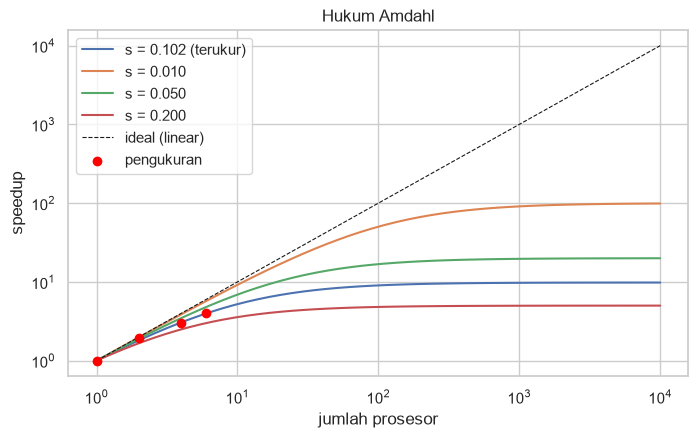

In [8]:
p_terbesar = skala.proses.max()
S_ukur = skala.set_index("proses").speedup[p_terbesar]
s_est = max((p_terbesar / S_ukur - 1) / (p_terbesar - 1), 1e-4) if p_terbesar > 1 else 0.05
print(f"Perkiraan fraksi serial s ≈ {s_est:.3f} (termasuk overhead membuat proses & mengirim data)")

p = np.logspace(0, 4, 50)
plt.figure(figsize=(8, 4.5))
for s in [s_est, 0.01, 0.05, 0.2]:
    plt.plot(p, 1 / (s + (1 - s) / p), label=f"s = {s:.3f}" + (" (terukur)" if s == s_est else ""))
plt.plot(p, p, "k--", lw=0.8, label="ideal (linear)")
plt.scatter(skala.proses, skala.speedup, color="red", zorder=5, label="pengukuran")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("jumlah prosesor"); plt.ylabel("speedup")
plt.title("Hukum Amdahl"); plt.legend(); plt.show()

## 3. Hasil simulasi: kebijakan mana yang paling hemat?

,kwh_rata,kwh_sd,biaya_juta,jam_tidak_nyaman,pelanggaran_bio,hemat_%,IK95_kwh
kebijakan,,,,,,,
P5 Kombinasi,37764.5,89.9,54.6,1858.9,0,40.4,27.9
P1 AC 08-17,47397.1,144.6,68.5,2817.4,0,25.2,44.8
P2 Setelan >= 25C,54303.2,153.4,78.5,0.0,0,14.3,47.5
P4 Lab tutup 20-08,56183.6,217.3,81.2,0.0,0,11.3,67.3
P3 Perpus tutup akhir pekan,61561.6,243.8,88.9,0.0,0,2.9,75.5
P0 Baseline,63371.6,267.5,91.6,0.0,0,0.0,82.9


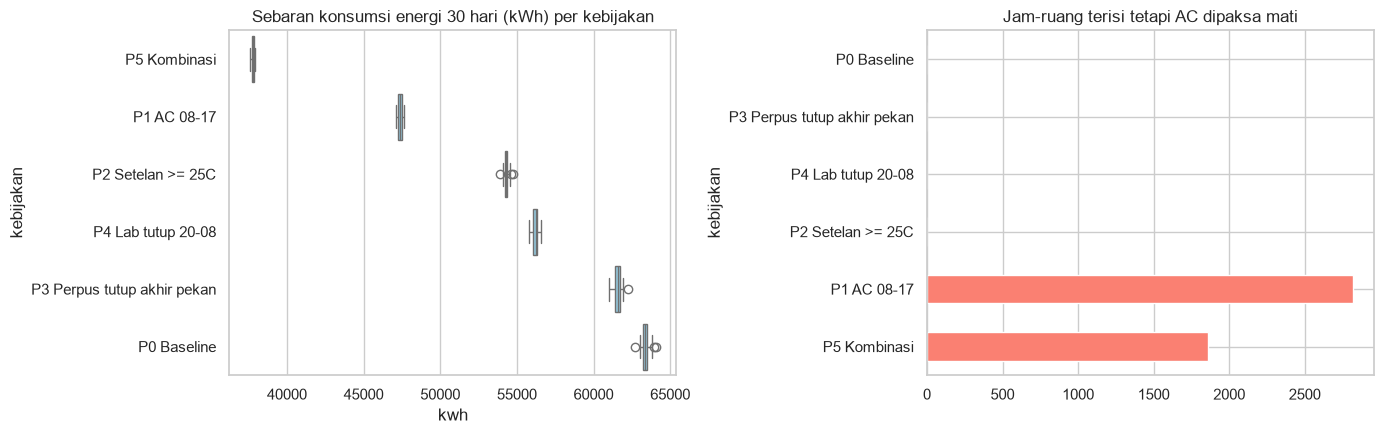

Perkiraan penghematan P5 per tahun: Rp443.933.843
Pelanggaran kendala lab biologi di semua kebijakan: 0


In [9]:
df = pd.DataFrame(hasil_serial)
ringkas = df.groupby("kebijakan").agg(kwh_rata=("kwh", "mean"), kwh_sd=("kwh", "std"),
                                      biaya_juta=("biaya_rp", lambda x: x.mean() / 1e6),
                                      jam_tidak_nyaman=("jam_tidak_nyaman", "mean"),
                                      pelanggaran_bio=("pelanggaran_bio", "sum"))
base = ringkas.loc["P0 Baseline", "kwh_rata"]
ringkas["hemat_%"] = 100 * (1 - ringkas.kwh_rata / base)
ringkas["IK95_kwh"] = 1.96 * ringkas.kwh_sd / np.sqrt(REPLIKASI)
display(ringkas.sort_values("kwh_rata").round(1))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
urut = ringkas.sort_values("kwh_rata").index
sns.boxplot(data=df, y="kebijakan", x="kwh", order=urut, ax=ax[0], color="skyblue")
ax[0].set_title("Sebaran konsumsi energi 30 hari (kWh) per kebijakan")
ringkas.loc[urut, "jam_tidak_nyaman"].plot(kind="barh", ax=ax[1], color="salmon")
ax[1].set_title("Jam-ruang terisi tetapi AC dipaksa mati"); plt.tight_layout(); plt.show()

hemat_tahun = (base - ringkas.loc["P5 Kombinasi", "kwh_rata"]) * 12 * sim_gedung.TARIF
print(f"Perkiraan penghematan P5 per tahun: Rp{hemat_tahun:,.0f}".replace(",", "."))
print("Pelanggaran kendala lab biologi di semua kebijakan:", int(ringkas.pelanggaran_bio.sum()))

**Interpretasi:** kebijakan dengan penghematan terbesar tidak selalu terbaik — P1 menghemat banyak tetapi menimbulkan
jam-ruang "tidak nyaman" (kuliah/praktikum sore tanpa AC). Pengelola kampus perlu menimbang **hemat vs gangguan
kegiatan akademik**, sesuai pesan pemateri bahwa kebijakan tidak boleh mengganggu riset & pengajaran.

## 4. Mengapa perlu HPC? Estimasi beban komputasi skala penuh

In [10]:
detik_per_replikasi_30hari = waktu[1] / len(tugas)
skenario = {"kebijakan": 50, "replikasi": 1000, "hari": 365, "gedung": 20}
total_detik = (detik_per_replikasi_30hari * skenario["hari"] / 30 * skenario["kebijakan"]
               * skenario["replikasi"] * skenario["gedung"])
print("Skenario penuh:", skenario)
for nama, core in [("Laptop/Colab (1 core)", 1), ("Colab (semua core)", N_CPU), ("1 node HPC (128 core)", 128),
                   ("16 node HPC (2048 core)", 2048)]:
    jam = total_detik / core / 3600
    print(f"{nama:28s}: {jam:>10,.1f} jam  (≈ {jam / 24:,.1f} hari)")

Skenario penuh: {'kebijakan': 50, 'replikasi': 1000, 'hari': 365, 'gedung': 20}
Laptop/Colab (1 core)       :      153.2 jam  (≈ 6.4 hari)
Colab (semua core)          :       25.5 jam  (≈ 1.1 hari)
1 node HPC (128 core)       :        1.2 jam  (≈ 0.0 hari)
16 node HPC (2048 core)     :        0.1 jam  (≈ 0.0 hari)


## 5. Membawa simulasi ke klaster HPC (SLURM)

Alur yang ditunjukkan pemateri: **buat kunci SSH → daftarkan kunci publik di portal → login terminal Linux →
unggah kode → tulis batch script → submit → unduh hasil → visualisasi.**

```bash
# di komputer sendiri (Linux/macOS/Windows PowerShell)
ssh-keygen -t ed25519 -C "nama@mahasiswa.unib.ac.id"   # menghasilkan kunci privat & publik (.pub)
# unggah ISI file ~/.ssh/id_ed25519.pub ke portal HPC, lalu:
ssh -i ~/.ssh/id_ed25519 username@login.hpc.contoh.id
```

Sel berikut membuat dua file: `run_kebijakan.py` (CLI untuk satu kebijakan) dan `job_simulasi.slurm`
(*job array*: satu tugas per kebijakan, masing-masing memakai banyak core).

In [11]:
RUN_PY = '''import argparse, json, os
from concurrent.futures import ProcessPoolExecutor
import sim_gedung

ap = argparse.ArgumentParser()
ap.add_argument("--indeks", type=int, required=True, help="indeks kebijakan (SLURM_ARRAY_TASK_ID)")
ap.add_argument("--replikasi", type=int, default=1000)
ap.add_argument("--hari", type=int, default=365)

def main():
    a = ap.parse_args()
    kebijakan = list(sim_gedung.KEBIJAKAN)[a.indeks]
    n_core = int(os.environ.get("SLURM_CPUS_PER_TASK", os.cpu_count()))
    tugas = [(kebijakan, s, a.hari) for s in range(a.replikasi)]
    with ProcessPoolExecutor(n_core) as ex:
        hasil = list(ex.map(sim_gedung.jalankan_tugas, tugas, chunksize=8))
    os.makedirs("hasil", exist_ok=True)
    with open(f"hasil/kebijakan_{a.indeks}.json", "w") as f:
        json.dump([{k: float(v) if k != "kebijakan" else v for k, v in h.items()} for h in hasil], f)
    print("selesai", kebijakan, len(hasil), "replikasi")

if __name__ == "__main__":     # wajib untuk multiprocessing
    main()
'''
SLURM = '''#!/bin/bash
#SBATCH --job-name=sim-gedung-unib
#SBATCH --partition=short            # sesuaikan dengan partisi di klaster Anda
#SBATCH --array=0-5                  # 6 kebijakan → 6 tugas paralel
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=32           # core per kebijakan
#SBATCH --mem=8G
#SBATCH --time=02:00:00
#SBATCH --output=log/%x_%A_%a.out

module load python/3.11              # nama modul berbeda di tiap klaster: cek `module avail`
source ~/venv-sim/bin/activate
python run_kebijakan.py --indeks ${SLURM_ARRAY_TASK_ID} --replikasi 1000 --hari 365
'''
open("run_kebijakan.py", "w", encoding="utf-8").write(RUN_PY)
open("job_simulasi.slurm", "w", encoding="utf-8", newline="\n").write(SLURM)   # akhir baris gaya Linux
print(SLURM)
print("Perintah di klaster:  mkdir -p log && sbatch job_simulasi.slurm   |   squeue -u $USER   |   sacct -j <JOBID>")

#!/bin/bash
#SBATCH --job-name=sim-gedung-unib
#SBATCH --partition=short            # sesuaikan dengan partisi di klaster Anda
#SBATCH --array=0-5                  # 6 kebijakan → 6 tugas paralel
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=32           # core per kebijakan
#SBATCH --mem=8G
#SBATCH --time=02:00:00
#SBATCH --output=log/%x_%A_%a.out

module load python/3.11              # nama modul berbeda di tiap klaster: cek `module avail`
source ~/venv-sim/bin/activate
python run_kebijakan.py --indeks ${SLURM_ARRAY_TASK_ID} --replikasi 1000 --hari 365

Perintah di klaster:  mkdir -p log && sbatch job_simulasi.slurm   |   squeue -u $USER   |   sacct -j <JOBID>


In [12]:
# Uji cepat script CLI di Colab (versi kecil) — memastikan kode siap sebelum dikirim ke klaster
import subprocess, sys
out = subprocess.run([sys.executable, "run_kebijakan.py", "--indeks", "5", "--replikasi", "4", "--hari", "7"],
                     capture_output=True, text=True)
print(out.stdout or out.stderr)

selesai P5 Kombinasi 4 replikasi



## 6. Peran *integrator* dalam studi kasus ini

```
Masalah lokal          Data & domain             Model & kode            Komputasi            Pengguna
(tagihan listrik) ──► (jadwal kuliah, daya AC, ──► (agent-based sim, ──► (Colab → HPC  ──► (dashboard
                       tarif PLN, pakar           Python, seed,          SLURM job array)     kebijakan untuk
                       fasilitas & biologi)       validasi)                                   pimpinan kampus)
```

Mahasiswa informatika menguasai bagian kode dan komputasi, tetapi **wajib** bekerja sama dengan pakar domain
(bagian sarana-prasarana, dosen biologi, PLN) agar asumsi model valid — persis pesan pemateri tentang kolaborasi lintas
keahlian.

## 7. Kesimpulan

* Pustaka numerik yang dioptimalkan (BLAS) memberi lompatan GFLOPS ribuan kali dibanding *loop* Python — optimasi
  algoritma dulu, baru tambah prosesor.
* Simulasi Monte Carlo bersifat *embarrassingly parallel*; *speedup* nyata dibatasi fraksi serial & *overhead*
  (Hukum Amdahl).
* Dalam model ini, kebijakan kombinasi (P5) memberi penghematan terbesar, sementara pembatasan jam AC perlu
  dikompensasi agar kegiatan sore tidak terganggu. Kendala lab biologi tetap terpenuhi.
* Skala penuh (banyak gedung × setahun × ribuan replikasi) memerlukan ratusan–ribuan jam-core → alasan nyata untuk
  memakai klaster HPC melalui *batch script* SLURM.

**Keterbatasan:** model fisik gedung sangat disederhanakan (bukan EnergyPlus), profil kehadiran & daya alat
adalah asumsi yang harus dikalibrasi dengan data meteran listrik kampus.